# Árbol de decisión

Supongamos que va a haber un concierto. La idea es que nosotros tenemos una tabla de actuación como la siguiente:

![Tabla de actuación para decidir si se debe ir o no al concierto](imagenes/01TablaParaGenerarElArbol.png)

La idea es que la IA pueda inferir, **sin programación estructura**, el siguiente árbol de decisiones. Observa que se parece un diagrama de flujo con condicionales. La idea es que la IA sea quien construya el diagrama sin la intervención de un programador:

![Árbol de decisión](imagenes/02arbolDeDecision.png)

El árbol de decisión tiene:

1. Una raíz
2. Ramas
3. Hojas que son las que contienen la decisión final

# Ejercicio de árboles de decisión

In [2]:
import pandas as pd
datos = pd.read_csv("train.csv" ,sep=',', encoding='utf-8')
datos.head(n=10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


5. Ahora veamos los datos estadísticos de todas las columnas **¿Faltan algunas columnas?**

In [3]:
datos.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


6. Elabora una gráfica de sobrevivientes

<Axes: xlabel='Survived', ylabel='count'>

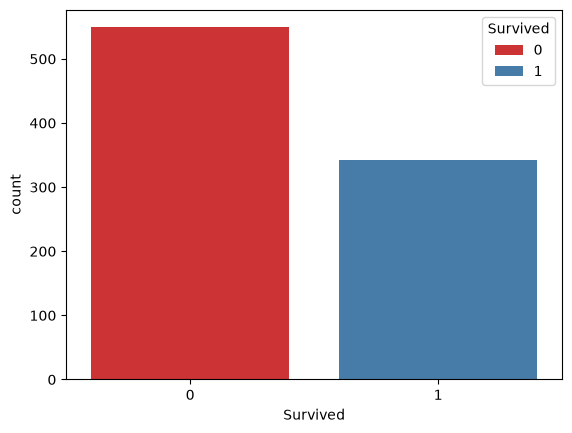

In [5]:
import seaborn as sb
sb.countplot(x='Survived', data=datos, hue='Survived', palette='Set1')

¿Hubo alguna tendencia en cuanto al sexo?

<Axes: xlabel='Survived', ylabel='count'>

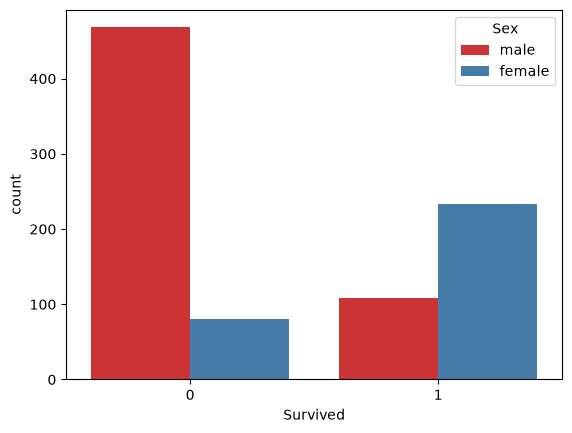

In [6]:
sb.countplot(x='Survived',data = datos, hue='Sex', palette='Set1')

Es importante verificar cuántos registros contienen datos vacíos (NA)

In [7]:
datos.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Como se puede observar, eliminar 177 registros correspondiente a _age_ es una pérdida de datos significativa: _Se podrían rellenar con el promedio_. Por el contrario, _cabin_ pudiera no ser muy importante y menos _Embarked_.

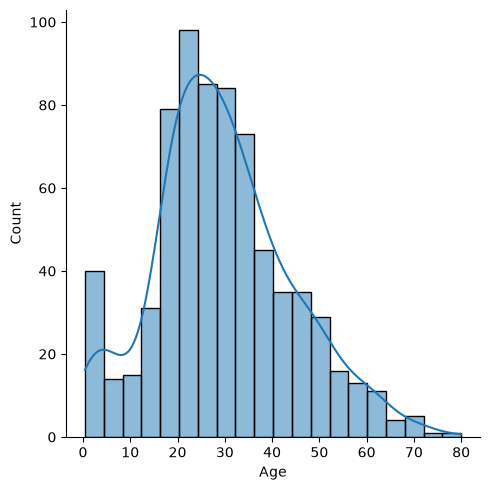

In [8]:
sb.displot(x='Age', data=datos, kde=True)

In [9]:
datos['Age'].mean()
datos.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
datos['Age'].fillna(datos['Age'].mean(), inplace=True)
datos.isna().sum()

C:\Users\BTC512\AppData\Local\Temp\ipykernel_6332\444128375.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  datos['Age'].fillna(datos['Age'].mean(), inplace=True)


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

¡Hay que eliminar los datos de la cabina!

In [11]:
datos.drop(['Cabin'], axis = 1,  inplace=True)

In [12]:
datos.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [13]:
datos.dropna(inplace=True)
datos.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [14]:
datos.head(15)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,C
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,S


¿Por qué también se deben eliminar las columnas _PassengerId_, _Name_, _Ticket_?

In [15]:
datos.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace=True)

In [16]:
datos.head(n=5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [17]:
datos.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,712.000000,712.000000,712.000000,712.000000,712.000000,712.000000
mean,0.404494,2.240169,29.642093,0.514045,0.432584,34.567251
std,0.491139,0.836854,14.492933,0.930692,0.854181,52.938648
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,20.000000,0.000000,0.000000,8.050000
50%,0.000000,2.000000,28.000000,0.000000,0.000000,15.645850
75%,1.000000,3.000000,38.000000,1.000000,1.000000,33.000000
max,1.000000,3.000000,80.000000,5.000000,6.000000,512.329200


Ahora hay que convertir la columna _Sex_ con get dummies

In [18]:
dummies_sex = pd.get_dummies(datos["Sex"], drop_first=True, dtype='int')
datos = datos.join(dummies_sex)
datos.drop(["Sex"],axis=1, inplace=True)
datos.head(n=5)

,Survived,Pclass,Age,SibSp,Parch,Fare,Embarked,male
0,0,3,22.0,1,0,7.2500,S,1
1,1,1,38.0,1,0,71.2833,C,0
2,1,3,26.0,0,0,7.9250,S,0
3,1,1,35.0,1,0,53.1000,S,0
4,0,3,35.0,0,0,8.0500,S,1


Ahora vamos a crear los dummies para la columna _Embarked_

<Axes: xlabel='Survived', ylabel='count'>

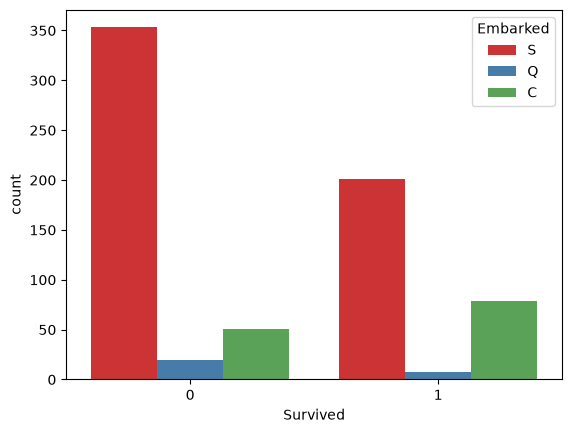

In [19]:
sb.countplot(x='Survived', data=datos, hue='Embarked', palette='Set1')

In [20]:
dummies_embarked = pd.get_dummies(datos["Embarked"], drop_first=True, dtype='int')
datos = datos.join(dummies_embarked)
datos.drop(["Embarked"], axis=1, inplace=True)
datos.head(n=5)

,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


Busquemos las correlaciones con un mapa de calor:

<Axes: >

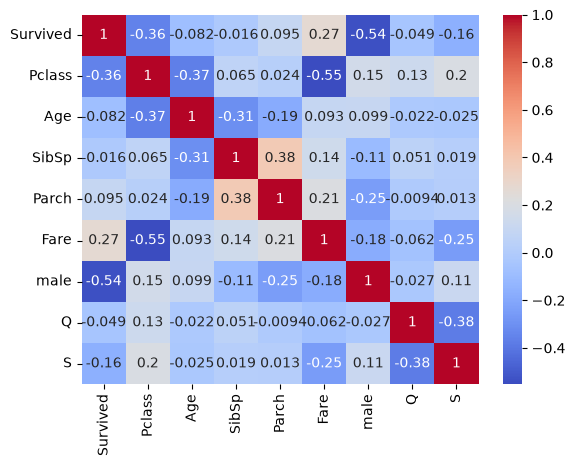

In [21]:
sb.heatmap(datos.corr(), annot=True, cmap='coolwarm')

Observa la relación entre la fila _Pclass_ y _Survived_. Veamos la relación que hay entre el mapa de calor anterior y el siguiente gráfico ¿Qué conclusión podemos obtener.

<Axes: xlabel='Survived', ylabel='count'>

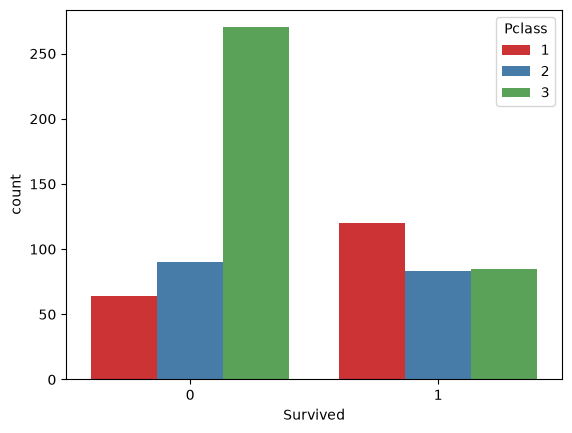

In [22]:
sb.countplot(x='Survived', data=datos, hue='Pclass', palette='Set1')

## Entrenamiento. Un nuevo enfoque

In [23]:
X= datos.drop(['Survived'], axis=1)
y= datos['Survived']

from sklearn.model_selection import train_test_split
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2)

Ahora usaremos otra clase: _DecisionTreeClassifier_ que, como se puede inferir de sunombre, ayuda a crear **modelos de árboles de decisión**. Observe que _max_depth_ ayuda a configurar la profundidad del entrenamiento:

In [24]:
from sklearn.tree import DecisionTreeClassifier
modelo = DecisionTreeClassifier(max_depth=50)
modelo.fit(X_ent, y_ent)
predicciones = modelo.predict(X_pru)

Ahora evaluemos el nuevo modelo con la clase _accuracy_score_. Eso nos permitirá verificar la calidad del nuevo modelo contra el obtenido en la regresión logística:

In [25]:
from sklearn.metrics import accuracy_score
accuracy_score (y_pru, predicciones)

0.7622377622377622

El nivel de profundidad _max_depth_ es importante para no causar una subrepresentación ni una sobrerrepresentación. Para ello, usemos un ciclo for para poder verificar el número de profundidad óptimo:

In [26]:
for i in range(1,15):
    modelo = DecisionTreeClassifier(max_depth=i)
    modelo.fit(X_ent, y_ent)
    predicciones = modelo.predict(X_pru)
    print(f"Profundidad: {i}, Precisión: {accuracy_score(y_pru, predicciones)}")

Profundidad: 1, Precisión: 0.7762237762237763
Profundidad: 2, Precisión: 0.8041958041958042
Profundidad: 3, Precisión: 0.8041958041958042
Profundidad: 4, Precisión: 0.8041958041958042
Profundidad: 5, Precisión: 0.8181818181818182
Profundidad: 6, Precisión: 0.8041958041958042
Profundidad: 7, Precisión: 0.7762237762237763
Profundidad: 8, Precisión: 0.8041958041958042
Profundidad: 9, Precisión: 0.7832167832167832
Profundidad: 10, Precisión: 0.8111888111888111
Profundidad: 11, Precisión: 0.8041958041958042
Profundidad: 12, Precisión: 0.7692307692307693
Profundidad: 13, Precisión: 0.7622377622377622
Profundidad: 14, Precisión: 0.7692307692307693


Para hacer una gráfica y no lidiar con tanto número, convendrá mejor almacenar los resultados en una lista vacía:

In [27]:
resultados = []
for i in range(1,15):
    modelo = DecisionTreeClassifier(max_depth=i)
    modelo.fit(X_ent, y_ent)
    predicciones = modelo.predict(X_pru)
    exactitud = accuracy_score(y_pru, predicciones)
    resultados.append(exactitud)

print(resultados)

[0.7762237762237763, 0.8041958041958042, 0.8041958041958042, 0.8041958041958042, 0.8181818181818182, 0.7902097902097902, 0.7902097902097902, 0.8111888111888111, 0.7972027972027972, 0.8181818181818182, 0.8041958041958042, 0.7762237762237763, 0.7692307692307693, 0.7482517482517482]


Ahora creemos un gráfico con las exactitudes:

<Axes: >

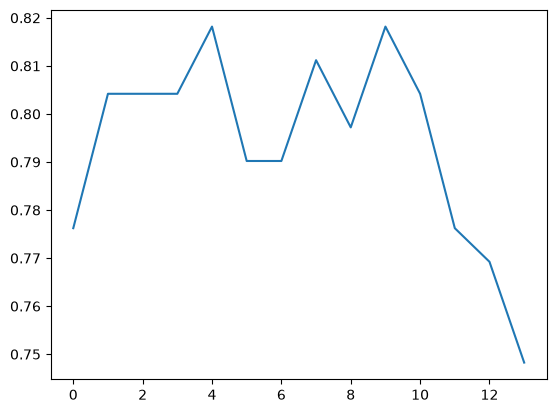

In [28]:
sb.lineplot(data=resultados)

¿Cuál nivel de profundidad parece ser el que entrega mejores niveles de confianza?

---

Con el resultado anterior, creemos el modelo estableciendo el nivel de profunidad:

In [29]:
modelo = DecisionTreeClassifier(max_depth=3)
modelo.fit(X_ent, y_ent)
predicciones = modelo.predict(X_pru)
print(f"Profundidad: {i}, Precisión: {accuracy_score(y_pru, predicciones)}")

Profundidad: 14, Precisión: 0.8041958041958042


Generemos nuestro reporte de clasificación. Observe el valor de _Accuracy_ en la columna _f1-score_:

In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_pru, predicciones))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85        90
           1       0.77      0.68      0.72        53

    accuracy                           0.80       143
   macro avg       0.79      0.78      0.78       143
weighted avg       0.80      0.80      0.80       143



Ahora creemos la matriz de confusión:

In [31]:
from sklearn.metrics import confusion_matrix
pd.DataFrame(confusion_matrix(y_pru, predicciones),columns=['Pred: No', 'Pred: Sí'], index=['Real No', 'Real Sí'])

,Pred: No,Pred: Sí
Real No,79,11
Real Sí,17,36


Ahora, procedamos a graficar el árbol ¡Sí! ¡Se puede graficar!

[Text(0.5, 0.875, 'male <= 0.5\ngini = 0.485\nsamples = 569\nvalue = [334, 235]\nclass = Murió'),
 Text(0.25, 0.625, 'Pclass <= 2.5\ngini = 0.357\nsamples = 206\nvalue = [48, 158]\nclass = Sobrevivió'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Age <= 2.5\ngini = 0.079\nsamples = 122\nvalue = [5, 117]\nclass = Sobrevivió'),
 Text(0.0625, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = Murió'),
 Text(0.1875, 0.125, 'gini = 0.064\nsamples = 121\nvalue = [4, 117]\nclass = Sobrevivió'),
 Text(0.375, 0.375, 'Fare <= 20.663\ngini = 0.5\nsamples = 84\nvalue = [43, 41]\nclass = Murió'),
 Text(0.3125, 0.125, 'gini = 0.484\nsamples = 68\nvalue = [28, 40]\nclass = Sobrevivió'),
 Text(0.4375, 0.125, 'gini = 0.117\nsamples = 16\nvalue = [15, 1]\nclass = Murió'),
 Text(0.75, 0.625, 'Age <= 9.5\ngini = 0.334\nsamples = 363\nvalue = [286, 77]\nclass = Murió'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'SibSp <= 2.5\ngini = 0.453\nsamples = 26\nvalue = [9, 17]\nclass = Sobrev

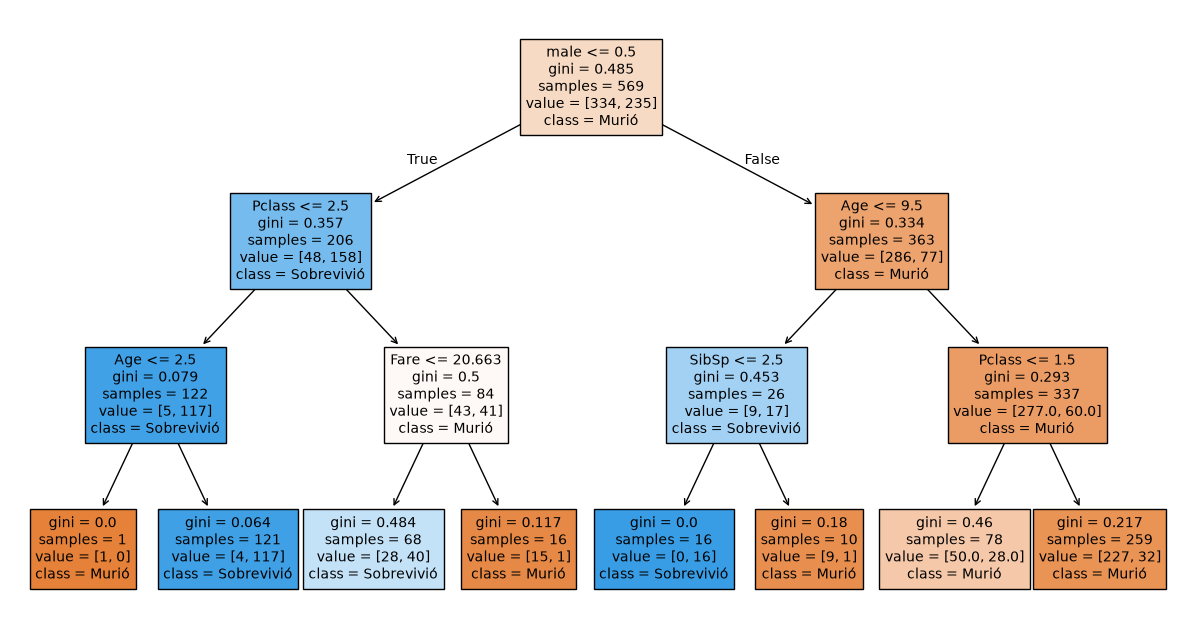

In [43]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))
plot_tree(modelo, filled=True, feature_names=X.columns, class_names=['Murió', 'Sobrevivió'], fontsize=10)

Se puede configurar el tamaño y guardar la imagen.


---

## Resultados obtenidos con la regresión logística

In [35]:
resultados

[0.7762237762237763,
 0.8041958041958042,
 0.8041958041958042,
 0.8041958041958042,
 0.8181818181818182,
 0.7902097902097902,
 0.7902097902097902,
 0.8111888111888111,
 0.7972027972027972,
 0.8181818181818182,
 0.8041958041958042,
 0.7762237762237763,
 0.7692307692307693,
 0.7482517482517482]

Ahora hagamos las pruebas:

In [36]:
predicciones = modelo.predict(X_pru)


In [37]:
from sklearn.metrics import accuracy_score
accuracy_score (y_pru, predicciones)

0.8041958041958042

¿Qué signfica el número anterior? Que la mayoría de las veces, las predicciones serán acertadas por el modelo, no por su precisión sino porque la mayoría de los pasajeros no sobrevivieron.

Para evitar ese problema, podemos importar _classification_report_ 

In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_pru, predicciones))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85        90
           1       0.77      0.68      0.72        53

    accuracy                           0.80       143
   macro avg       0.79      0.78      0.78       143
weighted avg       0.80      0.80      0.80       143



In [39]:
from sklearn.metrics import confusion_matrix

In [40]:
confusion_matrix(y_pru, predicciones)
pd.DataFrame(  confusion_matrix(y_pru, predicciones),columns=['Pred: No', 'Pred: Sí'], index=['Real No', 'Real Sí'])

,Pred: No,Pred: Sí
Real No,79,11
Real Sí,17,36


¿Qué significa la matriz anterior? 

* Localice la esquina superior derecha: Ese número indica que en 19 casos se había predicho que habían sobrevivido cuando en realidad no sobrevivieron (falso positivo).
* Localice la esquina inferior izquierda: El número indica cuantos casos el modelo predijo que no habían sobrevivido cuando en realidad sí lo hicieron (falso negativo).

## Predicción con una nueva persona

Crearemos a nueva persona para ver si habría sobrevivido o no:

In [41]:
datos.head(n=2)

,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0


In [42]:
nuevaPersona = pd.DataFrame([[3, 22, 0, 0, 10, 1, 0, 0]], 
                            columns=X_ent.columns) # Pclass, Age, SibSp, Parch, Fare
prediccion =  modelo.predict(nuevaPersona)
if prediccion[0] == 1:
    print("La persona sobrevivirá") 
else:
    print("La persona no sobrevivirá")  

La persona no sobrevivirá



¿que tanto yo contribuyo a la esclavitud digital con mi uso intensivo de la Ia?